In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
observables = ['evid','xsec','pt','n','parton','pt1','q1','eta1','direct1','pid1','tprod1','parent1','pt2','q2','eta2','direct2','pid2','tprod2','parent2']

In [4]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia1208_11pthat15_rc_truth_tprod.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia1208_15pthat20_rc_truth_tprod.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia1208_20pthat25_rc_truth_tprod.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia1208_25pthat30_rc_truth_tprod.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia1208_30pthat35_rc_truth_tprod.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia1208_35pthat40_rc_truth_tprod.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia1208_40pthat45_rc_truth_tprod.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia1208_45pthat50_rc_truth_tprod.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia1208_50pthat1000_rc_truth_tprod.txt']

In [5]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False, dtype={'tprod1':'double', 'tprod2':'double'})
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/20000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [6]:
df = applyCut(df, 'pt>15')

In [7]:
print('number of jets with q1 == -1:', df[df.q1==-1].shape[0])
print('number of jets with q1 == +1:', df[df.q1==1].shape[0])

number of jets with q1 == -1: 28230
number of jets with q1 == +1: 36769


In [36]:
df.eval('t1=tprod1/3e11', inplace=True)
df.eval('t2=tprod2/3e11', inplace=True)

(array([0.        , 0.        , 0.        , 0.        , 0.        ,
        0.44171308, 0.        , 0.        , 0.        , 0.        ]),
 array([-0.5, -0.4, -0.3, -0.2, -0.1,  0. ,  0.1,  0.2,  0.3,  0.4,  0.5]),
 [<matplotlib.patches.Polygon at 0x149b9cc2bdf0>])

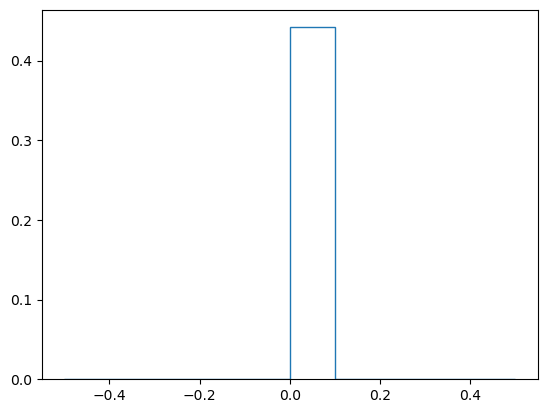

In [17]:
plt.hist(df[df.direct1>0]['tprod1'], weights=df[df.direct1>0]['w'], histtype='step')

In [34]:
np.average(df[df.direct1==0]['tprod1'], weights=df[df.direct1==0]['w'])

62364194415.4364

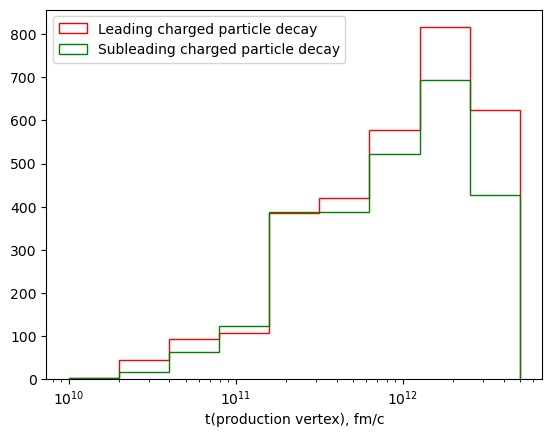

In [52]:
plt.hist(df[df.direct1==0]['tprod1'], weights=df[df.direct1==0]['w'], bins=np.logspace(np.log10(1e10),np.log10(5e12), 10), histtype='step', color='r', label='Leading charged particle decay')
#plt.hist(df[df.direct1>0]['tprod1'], weights=df[df.direct1>0]['w'], bins=np.logspace(np.log10(1e6),np.log10(1e13), 10), histtype='step')
plt.hist(df[df.direct2==0]['tprod2'], weights=df[df.direct2==0]['w'], bins=np.logspace(np.log10(1e10),np.log10(5e12), 10), histtype='step', color='g', label='Subleading charged particle decay')
#plt.hist(df[df.direct2>0]['tprod2'], weights=df[df.direct2>0]['w'], bins=np.logspace(np.log10(1e6),np.log10(1e13), 10), histtype='step')
plt.xscale('log')
plt.xlabel('t(production vertex), fm/c')
plt.legend()